# Lezione 13 — Caso Aula  
## Silicon Valley Bank 2023: piano ALM, sensitività e scenari di stress

### Prompt zero — Inizializzazione

Il Prompt zero ha inizializzato il contesto del corso, i Regimi A/B/C e le regole di lavoro.

Non produce una soluzione del caso e non modifica la Scheda Caso. La sequenza del notebook segue:

$$
\text{Prompt 1}
\longrightarrow
\text{Prompt 2}
\longrightarrow
\text{Prompt 3}
\longrightarrow
\text{prompt di tappa}.
$$

## Prompt 1 — Inquadramento del caso

La Scheda Caso costituisce la **specifica vincolante** del lavoro.

Il caso analizza un modello ALM deterministico stilizzato ispirato a Silicon Valley Bank. La banca sceglie l'allocazione iniziale tra quattro classi di attivo e gestisce nel tempo giacenze di liquidità e funding esterno.

I tre driver sono:

- $\theta$: intensità dei fabbisogni delle prime due date;
- $\phi$: capacità massima di funding;
- $\psi$: costo del funding, che modifica anche il rimborso del funding nelle date successive.

La domanda quantitativa è: **come cambia il piano ALM ottimo al variare separatamente e congiuntamente di fabbisogni, capacità e costo del funding, e fino a quale livello di aumento dei fabbisogni iniziali il problema resta ammissibile?**

### Quantità da calcolare

- benchmark: $x^*$, $g^*$, $u^*$, $\Pi^*$;
- residuali, slack, bounds attivi e marginali;
- sensitività univariate a $\theta$, $\phi$, $\psi$;
- variazioni assolute e percentuali rispetto al benchmark;
- utilizzo della capacità di funding;
- ultimo $\theta$ ammissibile, primo non ammissibile e intervallo raffinato contenente $\theta_{\mathrm{crit}}$;
- scenari Standard, Mediamente critico e Critico.

### Output richiesti

**10 tabelle**: parametri benchmark, soluzione benchmark, bilanci temporali, vincoli/bounds/slack, marginali, tre sensitività, frontiera raffinata, scenari.

**14 figure**: valore e variazione rispetto a $\theta$, asset allocation e sue variazioni, funding, giacenze, sensitività a $\phi$ e $\psi$, marginali, mappa vincoli attivi, quattro grafici di scenario.

### Controlli

Devono essere verificati stato solver, residuali, vincoli, bounds, non negatività, corretta azione dei tre driver, riproduzione del benchmark, corretta applicazione di $\psi$ sia all'obiettivo sia ai rimborsi, frontiera di fattibilità e uso esclusivo di risultati validi.

## Prompt 2 — Flusso logico-teorico risolutivo  
**Regime A**

| Passo | Finalità | Oggetto teorico | Applicazione | Output/controllo |
|---:|---|---|---|---|
| 1 | Ricostruire il PL-ALM | variabili, obiettivo, uguaglianze, disuguaglianze, bounds | identificare $x,g,u$ e tutti i vincoli | struttura teorica benchmark |
| 2 | Tradurre nella forma solver | $\max\Pi \leftrightarrow \min F=-\Pi$ | costruire $f,A_{eq},b_{eq},A_{ub},b_{ub}$ e bounds | controlli dimensionali e segni |
| 3 | Risolvere e validare il benchmark | fattibilità, residuali, slack | $(1,1,1)$ | $x^*,g^*,u^*,\Pi^*$ |
| 4 | Validare i marginali | dualità e sensitività locale | associare e perturbare almeno un termine noto | confronto marginale-perturbazione |
| 5 | Costruire il modello parametrico | analisi parametrica | introdurre $\theta,\phi,\psi$ solo dove previsto | funzione `solve_model` |
| 6 | Analizzare $\theta$ | comparative statics | stress prime due date | tabella e figure $\theta$ |
| 7 | Individuare la frontiera | insieme ammissibile parametrico | feasible $\to$ infeasible | intervallo di $\theta_{\mathrm{crit}}$ |
| 8 | Analizzare $\phi$ | bounds parametrizzati | capacità funding | tabella e figure $\phi$ |
| 9 | Analizzare $\psi$ | coefficienti obiettivo e rimborsi | costo funding | tabella e figure $\psi$ |
| 10 | Confrontare le sensitività | cambiamenti di regime | confronto separato dei driver | sintesi |
| 11 | Scenario analysis | configurazioni deterministiche | variazione congiunta | tabella e grafici scenari |
| 12 | Controlli conclusivi | coerenza modello-solver-output | riproducibilità e limiti | validazione finale |

## Prompt 3 — Scomposizione in tappe input-output  
**Regime A/B**

| Tappa | Titolo | Obiettivo | Input | Output | Controllo | Regime |
|---:|---|---|---|---|---|:---:|
| 1 | Forma solver | tradurre il modello | Scheda Caso | vettori, matrici, bounds | dimensioni, segni, ordine | A/B |
| 2 | Benchmark | risolvere e diagnosticare | forma solver | soluzione e tabelle benchmark | fattibilità e vincoli | B |
| 3 | Marginali | validare almeno un marginale | benchmark | confronto perturbativo | convenzione max/min | B |
| 4 | Solver parametrico | introdurre i tre driver | benchmark validato | funzione riutilizzabile | replica benchmark | A/B |
| 5 | Sensitività $\theta$ | stress fabbisogni | griglia $\theta$ | tabella e figure | unico driver, validità | B |
| 6 | Frontiera $\theta$ | localizzare perdita di fattibilità | risultati tappa 5 | intervallo raffinato | feasible/infeasible | B |
| 7 | Sensitività $\phi$ | capacità funding | griglia $\phi$ | tabella e figure | solo bounds funding | B |
| 8 | Sensitività $\psi$ | costo funding | griglia $\psi$ | tabella e figure | obiettivo + rimborsi | B |
| 9 | Confronto sensitività | leggere i tre driver | tappe 5-8 | sintesi | distinzione da scenari | A |
| 10 | Scenari | variazione congiunta | tre scenari | tabella e 4 figure | parametri esatti | B |
| 11 | Controlli finali | validare il notebook | tutti gli output | checklist | riproducibilità | A |

# Tappa 1 — Traduzione del modello nella forma solver  
**Regime A/B**

**Obiettivo.** Costruire la rappresentazione compatibile con `scipy.optimize.linprog`.

**Ordinamento vincolante**

$$
z=(x_1,x_2,x_3,x_4,g_1,g_2,g_3,g_4,u_1,u_2,u_3)'.
$$

**Controllo.** L'ordinamento resta invariato in tutto il notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

TOL = 1e-8

A0 = 100.0
c = np.array([0.010, 0.025, 0.040, 0.050])
ell = np.array([0.000, 0.020, 0.150, 0.080])

A_CF = np.array([
    [1.00, 0.65, 0.05, 0.05],
    [0.00, 0.35, 0.10, 0.15],
    [0.00, 0.00, 0.25, 0.30],
    [0.00, 0.00, 0.60, 0.50],
])

d_bench = np.array([30.0, 30.0, 22.0, 15.0])
r_g = np.array([0.005, 0.006, 0.007])
r_u = np.array([0.015, 0.020, 0.025])
u_bar = np.array([10.0, 8.0, 6.0])
K = 7.0
x3_max = 30.0

names = [f"x{i}" for i in range(1,5)] + [f"g{i}" for i in range(1,5)] + [f"u{i}" for i in range(1,4)]
idx = {name:i for i,name in enumerate(names)}
n_var = len(names)

print("Variabili:", names)
print("Numero variabili:", n_var)

Variabili: ['x1', 'x2', 'x3', 'x4', 'g1', 'g2', 'g3', 'g4', 'u1', 'u2', 'u3']
Numero variabili: 11


### Tabella 1 — Benchmark e parametri principali

La tabella rende verificabile la configurazione utilizzata dal solver. La matrice dei cash flow resta quella assegnata nella Scheda Caso.

In [2]:
tab_parametri = pd.DataFrame({
    "Quantità": ["A0","c","ell","d","r_g","r_u","u_bar","K","x3_max"],
    "Valore": [
        A0, c.tolist(), ell.tolist(), d_bench.tolist(),
        r_g.tolist(), r_u.tolist(), u_bar.tolist(), K, x3_max
    ]
})
display(tab_parametri)
display(pd.DataFrame(A_CF, index=["t1","t2","t3","t4"], columns=["x1","x2","x3","x4"]))

,Quantità,Valore
0,A0,100.0
1,c,"[0.01, 0.025, 0.04, 0.05]"
2,ell,"[0.0, 0.02, 0.15, 0.08]"
3,d,"[30.0, 30.0, 22.0, 15.0]"
4,r_g,"[0.005, 0.006, 0.007]"
5,r_u,"[0.015, 0.02, 0.025]"
6,u_bar,"[10.0, 8.0, 6.0]"
7,K,7.0
8,x3_max,30.0


,x1,x2,x3,x4
t1,1.0,0.65,0.05,0.05
t2,0.0,0.35,0.10,0.15
t3,0.0,0.00,0.25,0.30
t4,0.0,0.00,0.60,0.50


### Costruzione della forma solver benchmark

Il solver minimizza:

$$
F=-\Pi.
$$

Nel benchmark $\psi=1$. Il vettore obiettivo contiene quindi:

- $-c_j$ per gli attivi;
- $-r_t^g$ per $g_1,g_2,g_3$;
- coefficiente zero per $g_4$;
- $+r_t^u$ per il funding.

Le cinque uguaglianze sono il vincolo sulle risorse iniziali e i quattro bilanci temporali.

In [3]:
def build_problem(theta=1.0, phi=1.0, psi=1.0, d_override=None):
    d = np.array([30.0*theta, 30.0*theta, 22.0, 15.0]) if d_override is None else np.asarray(d_override, dtype=float)

    f = np.zeros(n_var)
    f[:4] = -c
    f[idx["g1"]:idx["g4"]] = -r_g
    f[idx["u1"]:idx["u3"]+1] = psi * r_u

    Aeq, beq = [], []

    row = np.zeros(n_var)
    row[:4] = 1.0
    Aeq.append(row); beq.append(A0)

    row = np.zeros(n_var)
    row[:4] = A_CF[0]
    row[idx["u1"]] = 1.0
    row[idx["g1"]] = -1.0
    Aeq.append(row); beq.append(d[0])

    row = np.zeros(n_var)
    row[:4] = A_CF[1]
    row[idx["g1"]] = 1.0 + r_g[0]
    row[idx["u1"]] = -(1.0 + psi*r_u[0])
    row[idx["u2"]] = 1.0
    row[idx["g2"]] = -1.0
    Aeq.append(row); beq.append(d[1])

    row = np.zeros(n_var)
    row[:4] = A_CF[2]
    row[idx["g2"]] = 1.0 + r_g[1]
    row[idx["u2"]] = -(1.0 + psi*r_u[1])
    row[idx["u3"]] = 1.0
    row[idx["g3"]] = -1.0
    Aeq.append(row); beq.append(d[2])

    row = np.zeros(n_var)
    row[:4] = A_CF[3]
    row[idx["g3"]] = 1.0 + r_g[2]
    row[idx["u3"]] = -(1.0 + psi*r_u[2])
    row[idx["g4"]] = -1.0
    Aeq.append(row); beq.append(d[3])

    Aub, bub = [], []

    row = np.zeros(n_var)
    row[:4] = ell
    Aub.append(row); bub.append(K)

    row = np.zeros(n_var)
    row[idx["x3"]] = 1.0
    Aub.append(row); bub.append(x3_max)

    bounds = [(0.0, None)] * 8 + [(0.0, phi*u_bar[t]) for t in range(3)]

    return (
        f, np.array(Aeq), np.array(beq),
        np.array(Aub), np.array(bub),
        bounds, d
    )

f, A_eq, b_eq, A_ub, b_ub, bounds, d0 = build_problem()

print("f:", f.shape)
print("A_eq:", A_eq.shape, "b_eq:", b_eq.shape)
print("A_ub:", A_ub.shape, "b_ub:", b_ub.shape)
print("bounds:", len(bounds))

f: (11,)
A_eq: (5, 11) b_eq: (5,)
A_ub: (2, 11) b_ub: (2,)
bounds: 11


### Controlli dimensionali e di coerenza

Devono risultare:

- 11 variabili;
- $A_{\mathrm{eq}}$ di dimensione $5\times 11$;
- $A_{\mathrm{ub}}$ di dimensione $2\times 11$;
- bounds di funding $(0,10)$, $(0,8)$, $(0,6)$ nel benchmark;
- riga di concentrazione coerente con $x_3\leq30$.

In [4]:
assert f.shape == (11,)
assert A_eq.shape == (5,11)
assert b_eq.shape == (5,)
assert A_ub.shape == (2,11)
assert b_ub.shape == (2,)
assert len(bounds) == 11
assert np.isclose(A_ub[1, idx["x3"]], 1.0)
assert np.isclose(b_ub[1], 30.0)
assert bounds[idx["u1"]] == (0.0,10.0)
assert bounds[idx["u2"]] == (0.0,8.0)
assert bounds[idx["u3"]] == (0.0,6.0)

print("Controlli forma solver: OK")

Controlli forma solver: OK


# Tappa 2 — Soluzione e validazione del benchmark  
**Regime B**

Si risolve:

$$
(\theta,\phi,\psi)=(1,1,1).
$$

Prima di usare la soluzione si controlla `success`. Il valore economico è ricostruito come $\Pi^*=-F^*$.

In [5]:
res_bench = linprog(
    f,
    A_ub=A_ub, b_ub=b_ub,
    A_eq=A_eq, b_eq=b_eq,
    bounds=bounds,
    method="highs"
)

print("success:", res_bench.success)
print("status :", res_bench.status)
print("message:", res_bench.message)

if not res_bench.success:
    raise RuntimeError("Benchmark non risolvibile.")

z_bench = res_bench.x
x_bench = z_bench[:4]
g_bench = z_bench[4:8]
u_bench = z_bench[8:11]
Pi_bench = -res_bench.fun

print("Pi* =", Pi_bench)

success: True
status : 0
message: Optimization terminated successfully. (HiGHS Status 7: Optimal)
Pi* = 3.5921659925406346


### Tabella 2 — Soluzione benchmark

La soluzione riporta tutte le variabili e il valore economico ottimo.

In [6]:
tab_soluzione = pd.DataFrame({"Variabile": names, "Valore ottimo": z_bench})
display(tab_soluzione)
display(pd.DataFrame({"Quantità":["Pi*"],"Valore":[Pi_bench]}))

,Variabile,Valore ottimo
0,x1,0.000000
1,x2,51.919684
2,x3,0.000000
3,x4,48.080316
4,g1,6.151810
5,g2,1.566506
6,g3,0.000000
7,g4,2.890158
8,u1,0.000000
9,u2,0.000000


,Quantità,Valore
0,Pi*,3.592166


### Tabella 3 — Verifica dei bilanci temporali

I bilanci vengono ricostruiti indipendentemente, distinguendo:

- cash flow degli attivi;
- giacenza precedente;
- funding corrente;
- rimborso del funding precedente;
- fabbisogno;
- giacenza finale;
- residuo.

In [7]:
rows = []
for t in range(4):
    cf = float(A_CF[t] @ x_bench)
    giac_prec = 0.0 if t == 0 else (1+r_g[t-1])*g_bench[t-1]
    fund_corr = 0.0 if t == 3 else u_bench[t]
    rimborso = 0.0 if t == 0 else (1+r_u[t-1])*u_bench[t-1]
    g_finale = g_bench[t]
    lhs = cf + giac_prec + fund_corr - rimborso - g_finale
    rows.append({
        "data": t+1,
        "cash_flow_attivi": cf,
        "giacenza_precedente": giac_prec,
        "funding_corrente": fund_corr,
        "rimborso_funding": rimborso,
        "fabbisogno": d_bench[t],
        "giacenza_finale": g_finale,
        "residuo": lhs-d_bench[t]
    })
tab_bilanci = pd.DataFrame(rows)
display(tab_bilanci)

assert np.max(np.abs(tab_bilanci["residuo"])) < 1e-7

,data,cash_flow_attivi,giacenza_precedente,funding_corrente,rimborso_funding,fabbisogno,giacenza_finale,residuo
0,1,36.151810,0.000000,0.0,0.00,30.0,6.151810,-3.552714e-15
1,2,25.383937,6.182569,0.0,0.00,30.0,1.566506,7.105427e-15
2,3,14.424095,1.575905,6.0,0.00,22.0,0.000000,0.000000e+00
3,4,24.040158,0.000000,0.0,6.15,15.0,2.890158,0.000000e+00


### Tabella 4 — Vincoli, bounds e slack benchmark

Si distinguono disuguaglianze esplicite e bounds sulle variabili.

In [8]:
ub_slack = b_ub - A_ub @ z_bench
eq_res = A_eq @ z_bench - b_eq

rows = [
    {
        "restrizione":"prudenziale",
        "valore":float(ell @ x_bench),
        "limite":K,
        "slack_distanza":ub_slack[0],
        "attivo":abs(ub_slack[0])<=TOL
    },
    {
        "restrizione":"x3_max",
        "valore":x_bench[2],
        "limite":x3_max,
        "slack_distanza":ub_slack[1],
        "attivo":abs(ub_slack[1])<=TOL
    }
]

for j,(lo,hi) in enumerate(bounds):
    val = z_bench[j]
    if lo is not None:
        rows.append({
            "restrizione":f"{names[j]} lower",
            "valore":val,
            "limite":lo,
            "slack_distanza":val-lo,
            "attivo":abs(val-lo)<=TOL
        })
    if hi is not None:
        rows.append({
            "restrizione":f"{names[j]} upper",
            "valore":val,
            "limite":hi,
            "slack_distanza":hi-val,
            "attivo":abs(hi-val)<=TOL
        })

tab_vincoli = pd.DataFrame(rows)
display(tab_vincoli)

assert np.max(np.abs(eq_res)) < 1e-7
assert np.all(ub_slack >= -1e-7)
assert np.min(z_bench) >= -1e-7

,restrizione,valore,limite,slack_distanza,attivo
0,prudenziale,4.884819,7.0,2.115181,False
1,x3_max,0.000000,30.0,30.000000,False
2,x1 lower,0.000000,0.0,0.000000,True
3,x2 lower,51.919684,0.0,51.919684,False
4,x3 lower,0.000000,0.0,0.000000,True
5,x4 lower,48.080316,0.0,48.080316,False
6,g1 lower,6.151810,0.0,6.151810,False
7,g2 lower,1.566506,0.0,1.566506,False
8,g3 lower,0.000000,0.0,0.000000,True
9,g4 lower,2.890158,0.0,2.890158,False


### Tabella 5 — Valori marginali benchmark

I marginali sono quantità **locali**.

Per le uguaglianze `linprog` restituisce:

$$
m_i=\frac{\partial F^*}{\partial b_i}.
$$

Poiché $F=-\Pi$:

$$
\frac{\partial\Pi^*}{\partial b_i}=-m_i.
$$

Per i bounds di funding vengono inoltre riportati i marginali superiori restituiti dal solver.

In [9]:
eq_labels = ["risorse","bilancio_t1","bilancio_t2","bilancio_t3","bilancio_t4"]

marg_rows = []
for lab, m in zip(eq_labels, res_bench.eqlin.marginals):
    marg_rows.append({
        "oggetto":lab,
        "tipo":"uguaglianza",
        "marginale_F":m,
        "marginale_Pi_rispetto_RHS":-m
    })

for lab, m in zip(["prudenziale","x3_max"], res_bench.ineqlin.marginals):
    marg_rows.append({
        "oggetto":lab,
        "tipo":"disuguaglianza",
        "marginale_F":m,
        "marginale_Pi_rispetto_RHS":-m
    })

for k,name in enumerate(names):
    um = res_bench.upper.marginals[k]
    if abs(um) > TOL or (bounds[k][1] is not None and abs(z_bench[k]-bounds[k][1])<=TOL):
        marg_rows.append({
            "oggetto":f"{name}_upper",
            "tipo":"bound superiore",
            "marginale_F":um,
            "marginale_Pi_rispetto_RHS":-um
        })

tab_marginali = pd.DataFrame(marg_rows)
display(tab_marginali)

,oggetto,tipo,marginale_F,marginale_Pi_rispetto_RHS
0,risorse,uguaglianza,-0.068418,0.068418
1,bilancio_t1,uguaglianza,0.045238,-0.045238
2,bilancio_t2,uguaglianza,0.040038,-0.040038
3,bilancio_t3,uguaglianza,0.033835,-0.033835
4,bilancio_t4,uguaglianza,-0.000000,0.000000
5,prudenziale,disuguaglianza,-0.000000,0.000000
6,x3_max,disuguaglianza,-0.000000,0.000000
7,u3_upper,bound superiore,-0.008835,0.008835


# Tappa 3 — Verifica numerica di un valore marginale  
**Regime B**

Verifichiamo il marginale del termine noto del **bilancio alla data 1**, perturbando il relativo RHS di una quantità piccola $\varepsilon$.

Per una uguaglianza:

$$
m=\frac{\partial F^*}{\partial b},
\qquad
\frac{\partial\Pi^*}{\partial b}=-m.
$$

La verifica è valida localmente se la perturbazione non determina un cambio di regime.

In [10]:
eps = 1e-4
m_t1 = float(res_bench.eqlin.marginals[1])

b_eq_pert = b_eq.copy()
b_eq_pert[1] += eps

res_pert = linprog(
    f,
    A_ub=A_ub, b_ub=b_ub,
    A_eq=A_eq, b_eq=b_eq_pert,
    bounds=bounds,
    method="highs"
)
if not res_pert.success:
    raise RuntimeError("Perturbazione del bilancio t1 non risolvibile.")

Pi_pert = -res_pert.fun
num_der = (Pi_pert - Pi_bench)/eps
expected = -m_t1

tab_check_marg = pd.DataFrame({
    "quantita":["m_solver_F","-m_solver = dPi/db","derivata_numerica","errore_assoluto"],
    "valore":[m_t1, expected, num_der, abs(num_der-expected)]
})
display(tab_check_marg)

assert abs(num_der-expected) < 1e-6
print("Verifica marginale locale: OK")

,quantita,valore
0,m_solver_F,4.523816e-02
1,-m_solver = dPi/db,-4.523816e-02
2,derivata_numerica,-4.523816e-02
3,errore_assoluto,4.304071e-12


Verifica marginale locale: OK


### Interpretazione locale del marginale verificato

Il controllo conferma la coerenza tra marginale solver e variazione numerica del valore economico.

Il marginale non va interpretato come relazione globale: quando cambia l'insieme dei vincoli o bounds attivi, può cambiare anche la derivata locale del valore ottimo.

# Tappa 4 — Costruzione del solver parametrico  
**Regime A/B**

La funzione:

$$
\operatorname{solve}(\theta,\phi,\psi)
$$

deve rispettare tre regole:

1. $\theta$ modifica solo i fabbisogni delle prime due date;
2. $\phi$ modifica solo i limiti superiori del funding;
3. $\psi$ modifica **sia** il costo del funding nell'obiettivo **sia** il rimborso del funding nei bilanci.

Il primo controllo è la riproduzione del benchmark in $(1,1,1)$.

In [11]:
def solve_model(theta=1.0, phi=1.0, psi=1.0):
    f_loc, Aeq, beq, Aub, bub, bnds, d = build_problem(theta,phi,psi)

    res = linprog(
        f_loc,
        A_ub=Aub, b_ub=bub,
        A_eq=Aeq, b_eq=beq,
        bounds=bnds,
        method="highs"
    )

    out = {
        "theta":theta, "phi":phi, "psi":psi,
        "success":bool(res.success), "status":int(res.status), "message":res.message
    }
    if not res.success:
        return out

    z = res.x
    x,g,u = z[:4], z[4:8], z[8:11]

    out.update({
        "Pi":-res.fun,
        "z":z, "x":x, "g":g, "u":u,
        "eq_residuals":Aeq@z-beq,
        "ub_slacks":bub-Aub@z,
        "eq_marginals":res.eqlin.marginals,
        "ub_marginals":res.ineqlin.marginals,
        "lower_marginals":res.lower.marginals,
        "upper_marginals":res.upper.marginals,
        "bounds":bnds,
        "d":d
    })
    return out

bench_fun = solve_model(1,1,1)
assert bench_fun["success"]
assert np.allclose(bench_fun["z"], z_bench, atol=1e-8)
assert np.isclose(bench_fun["Pi"], Pi_bench, atol=1e-10)

print("Funzione parametrica = benchmark diretto: OK")

Funzione parametrica = benchmark diretto: OK


# Tappa 5 — Sensitività rispetto a $\theta$  
**Regime B**

Si usa la griglia:

$$
\theta\in\{1.00,1.01,\ldots,1.10\},
$$

con $\phi=\psi=1$.

Per ogni punto si registra lo stato del solver. Le quantità ottime sono utilizzate soltanto quando la configurazione è ammissibile.

In [12]:
def row_from_solution(out, varying_name, varying_value):
    row = {
        varying_name:varying_value,
        "success":out["success"],
        "status":out["status"]
    }
    if not out["success"]:
        return row

    row["Pi"] = out["Pi"]
    row["Delta_Pi"] = out["Pi"] - Pi_bench
    row["Delta_Pi_pct"] = 100*(out["Pi"]/Pi_bench - 1.0)

    for j in range(4):
        row[f"x{j+1}"] = out["x"][j]
        row[f"Delta_x{j+1}"] = out["x"][j]-x_bench[j]
    for t in range(4):
        row[f"g{t+1}"] = out["g"][t]
        row[f"Delta_g{t+1}"] = out["g"][t]-g_bench[t]
    for t in range(3):
        row[f"u{t+1}"] = out["u"][t]
        row[f"Delta_u{t+1}"] = out["u"][t]-u_bench[t]
        cap = out["phi"]*u_bar[t]
        row[f"rho_u{t+1}"] = out["u"][t]/cap if cap>0 else np.nan

    row["prud_slack"] = out["ub_slacks"][0]
    row["x3_slack"] = out["ub_slacks"][1]
    row["u1_upper_slack"] = out["bounds"][8][1]-out["u"][0]
    row["u2_upper_slack"] = out["bounds"][9][1]-out["u"][1]
    row["u3_upper_slack"] = out["bounds"][10][1]-out["u"][2]
    row["marg_t1_Pi"] = -out["eq_marginals"][1]
    row["marg_t2_Pi"] = -out["eq_marginals"][2]
    row["marg_t3_Pi"] = -out["eq_marginals"][3]
    row["marg_t4_Pi"] = -out["eq_marginals"][4]
    return row

theta_grid = np.round(np.arange(1.00,1.101,0.01),2)
theta_rows=[]
for q in theta_grid:
    outq=solve_model(theta=float(q),phi=1,psi=1)
    theta_rows.append(row_from_solution(outq,"theta",q))
df_theta=pd.DataFrame(theta_rows)

# Tabella 6
display(df_theta)

,theta,success,status,Pi,Delta_Pi,Delta_Pi_pct,x1,Delta_x1,x2,Delta_x2,x3,Delta_x3,x4,Delta_x4,g1,Delta_g1,g2,Delta_g2,g3,Delta_g3,g4,Delta_g4,u1,Delta_u1,rho_u1,u2,Delta_u2,rho_u2,u3,Delta_u3,rho_u3,prud_slack,x3_slack,u1_upper_slack,u2_upper_slack,u3_upper_slack,marg_t1_Pi,marg_t2_Pi,marg_t3_Pi,marg_t4_Pi
0,1.00,True,0,3.592166,0.000000,0.000000,0.000000,0.000000,51.919684,0.000000,0.0,0.0,48.080316,0.000000,6.151810,0.000000,1.566506,0.000000,0.00000,0.00000,2.890158,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,6.00000,0.00000,1.000000,2.115181,30.0,10.0,8.0,0.00000,-0.045238,-0.040038,-0.033835,0.000000
1,1.01,True,0,3.566583,-0.025583,-0.712184,0.000000,0.000000,53.111270,1.191586,0.0,0.0,46.888730,-1.191586,6.566762,0.414952,1.921850,0.355344,0.00000,0.00000,2.294365,-0.595793,0.0,0.0,0.0,0.0,0.0,0.0,6.00000,0.00000,1.000000,2.186676,30.0,10.0,8.0,0.00000,-0.045238,-0.040038,-0.033835,0.000000
2,1.02,True,0,3.541000,-0.051166,-1.424368,0.000000,0.000000,54.302857,2.383173,0.0,0.0,45.697143,-2.383173,6.981714,0.829904,2.277194,0.710688,0.00000,0.00000,1.698572,-1.191586,0.0,0.0,0.0,0.0,0.0,0.0,6.00000,0.00000,1.000000,2.258171,30.0,10.0,8.0,0.00000,-0.045238,-0.040038,-0.033835,0.000000
3,1.03,True,0,3.515417,-0.076749,-2.136552,0.000000,0.000000,55.494443,3.574759,0.0,0.0,44.505557,-3.574759,7.396666,1.244855,2.632538,1.066032,0.00000,0.00000,1.102779,-1.787380,0.0,0.0,0.0,0.0,0.0,0.0,6.00000,0.00000,1.000000,2.329667,30.0,10.0,8.0,0.00000,-0.045238,-0.040038,-0.033835,0.000000
4,1.04,True,0,3.489835,-0.102331,-2.848737,0.000000,0.000000,56.686029,4.766345,0.0,0.0,43.313971,-4.766345,7.811618,1.659807,2.987881,1.421375,0.00000,0.00000,0.506985,-2.383173,0.0,0.0,0.0,0.0,0.0,0.0,6.00000,0.00000,1.000000,2.401162,30.0,10.0,8.0,0.00000,-0.045238,-0.040038,-0.033835,0.000000
5,1.05,True,0,3.444828,-0.147338,-4.101636,0.000000,0.000000,62.206863,10.287179,0.0,0.0,37.793137,-10.287179,10.824118,4.672308,6.819611,5.253105,0.00000,0.00000,0.000000,-2.890158,0.0,0.0,0.0,0.0,0.0,0.0,3.80153,-2.19847,0.633588,2.732412,30.0,10.0,8.0,2.19847,-0.262959,-0.256675,-0.249180,-0.218713
6,1.06,True,0,2.159921,-1.432245,-39.871336,62.671906,62.671906,37.328094,-14.591590,0.0,0.0,0.000000,-48.080316,55.135167,48.983357,36.675676,35.109170,14.89573,14.89573,0.000000,-2.890158,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,-6.00000,0.000000,6.253438,30.0,10.0,8.0,6.00000,-7.614286,-7.571429,-7.520307,-7.461079
7,1.07,False,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,1.08,False,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,1.09,False,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Figure 1–6 e 9–10 — Sensitività a $\theta$

La sensitività a $\theta$ è la più ricca perché serve anche a individuare la frontiera di fattibilità.

I grafici non collegano punti non ammissibili.

<>:53: SyntaxWarning: invalid escape sequence '\P'
<>:53: SyntaxWarning: invalid escape sequence '\P'
/tmp/ipykernel_1371/1086104655.py:53: SyntaxWarning: invalid escape sequence '\P'
  plt.xlabel(r"$\theta$"); plt.ylabel("Marginale di $\Pi^*$ rispetto al RHS")


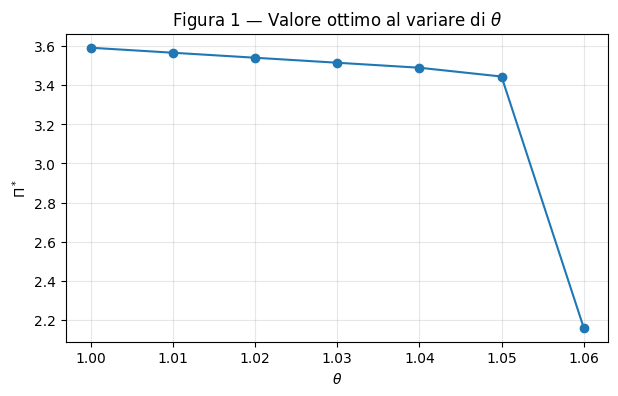

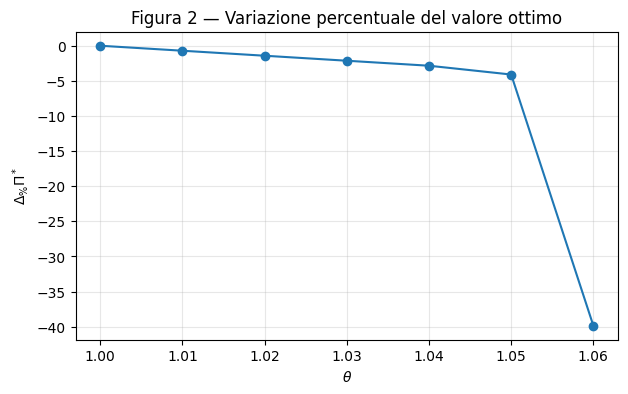

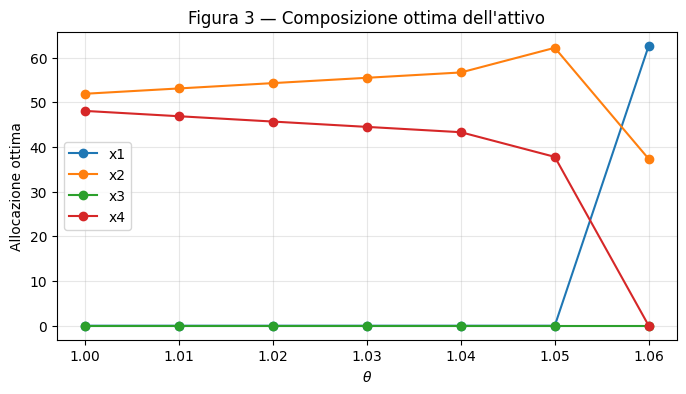

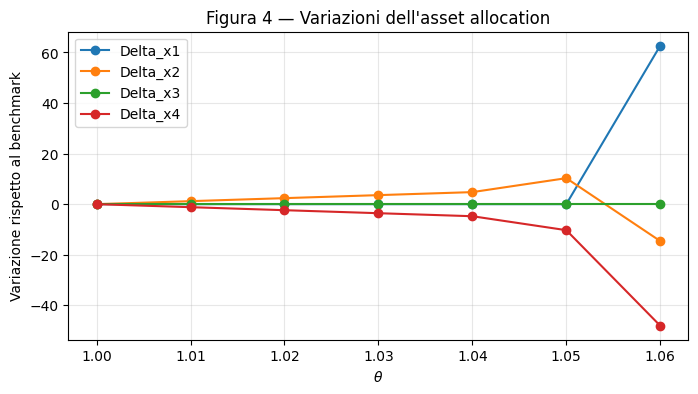

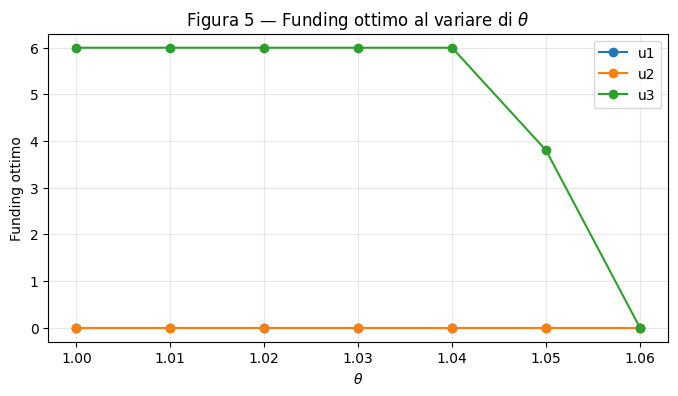

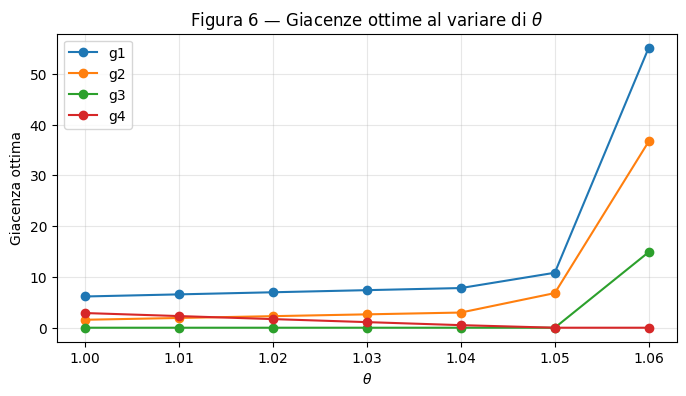

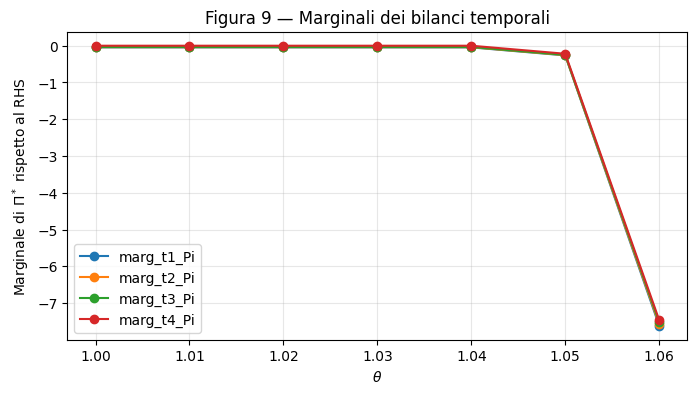

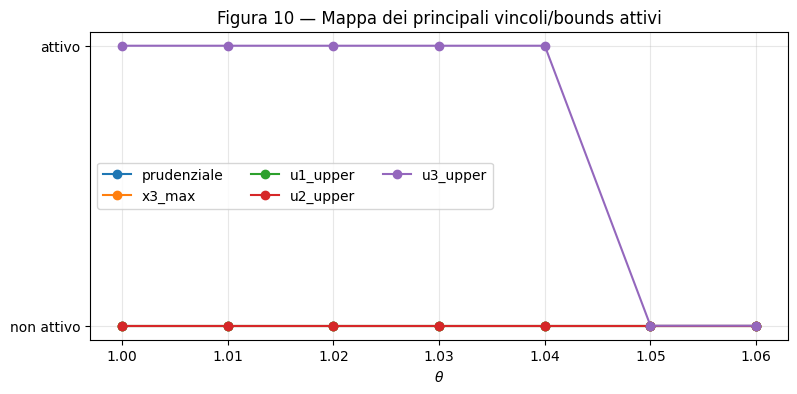

In [13]:
valid_theta=df_theta[df_theta["success"]].copy()

# Figura 1
plt.figure(figsize=(7,4))
plt.plot(valid_theta["theta"], valid_theta["Pi"], marker="o")
plt.xlabel(r"$\theta$"); plt.ylabel(r"$\Pi^*$")
plt.title(r"Figura 1 — Valore ottimo al variare di $\theta$")
plt.grid(True,alpha=.3); plt.show()

# Figura 2
plt.figure(figsize=(7,4))
plt.plot(valid_theta["theta"], valid_theta["Delta_Pi_pct"], marker="o")
plt.xlabel(r"$\theta$"); plt.ylabel(r"$\Delta_{\%}\Pi^*$")
plt.title(r"Figura 2 — Variazione percentuale del valore ottimo")
plt.grid(True,alpha=.3); plt.show()

# Figura 3
plt.figure(figsize=(8,4))
for col in ["x1","x2","x3","x4"]:
    plt.plot(valid_theta["theta"], valid_theta[col], marker="o", label=col)
plt.xlabel(r"$\theta$"); plt.ylabel("Allocazione ottima")
plt.title(r"Figura 3 — Composizione ottima dell'attivo")
plt.legend(); plt.grid(True,alpha=.3); plt.show()

# Figura 4
plt.figure(figsize=(8,4))
for col in ["Delta_x1","Delta_x2","Delta_x3","Delta_x4"]:
    plt.plot(valid_theta["theta"], valid_theta[col], marker="o", label=col)
plt.xlabel(r"$\theta$"); plt.ylabel("Variazione rispetto al benchmark")
plt.title("Figura 4 — Variazioni dell'asset allocation")
plt.legend(); plt.grid(True,alpha=.3); plt.show()

# Figura 5
plt.figure(figsize=(8,4))
for col in ["u1","u2","u3"]:
    plt.plot(valid_theta["theta"], valid_theta[col], marker="o", label=col)
plt.xlabel(r"$\theta$"); plt.ylabel("Funding ottimo")
plt.title(r"Figura 5 — Funding ottimo al variare di $\theta$")
plt.legend(); plt.grid(True,alpha=.3); plt.show()

# Figura 6
plt.figure(figsize=(8,4))
for col in ["g1","g2","g3","g4"]:
    plt.plot(valid_theta["theta"], valid_theta[col], marker="o", label=col)
plt.xlabel(r"$\theta$"); plt.ylabel("Giacenza ottima")
plt.title(r"Figura 6 — Giacenze ottime al variare di $\theta$")
plt.legend(); plt.grid(True,alpha=.3); plt.show()

# Figura 9
plt.figure(figsize=(8,4))
for col in ["marg_t1_Pi","marg_t2_Pi","marg_t3_Pi","marg_t4_Pi"]:
    plt.plot(valid_theta["theta"], valid_theta[col], marker="o", label=col)
plt.xlabel(r"$\theta$"); plt.ylabel("Marginale di $\Pi^*$ rispetto al RHS")
plt.title("Figura 9 — Marginali dei bilanci temporali")
plt.legend(); plt.grid(True,alpha=.3); plt.show()

# Figura 10
active_map = pd.DataFrame({
    "theta":valid_theta["theta"],
    "prudenziale":np.isclose(valid_theta["prud_slack"],0,atol=1e-7).astype(int),
    "x3_max":np.isclose(valid_theta["x3_slack"],0,atol=1e-7).astype(int),
    "u1_upper":np.isclose(valid_theta["u1_upper_slack"],0,atol=1e-7).astype(int),
    "u2_upper":np.isclose(valid_theta["u2_upper_slack"],0,atol=1e-7).astype(int),
    "u3_upper":np.isclose(valid_theta["u3_upper_slack"],0,atol=1e-7).astype(int),
})
plt.figure(figsize=(9,4))
for col in active_map.columns[1:]:
    plt.plot(active_map["theta"], active_map[col], marker="o", label=col)
plt.yticks([0,1],["non attivo","attivo"])
plt.xlabel(r"$\theta$")
plt.title("Figura 10 — Mappa dei principali vincoli/bounds attivi")
plt.legend(ncol=3); plt.grid(True,alpha=.3); plt.show()

# Tappa 6 — Frontiera di fattibilità rispetto a $\theta$  
**Regime B**

La griglia iniziale deve fornire:

- ultimo valore ammissibile;
- primo valore successivo non ammissibile.

Il raffinamento viene effettuato **solo** nell'intervallo così individuato.

La frontiera è proprietà del modello stilizzato, non una stima storica dei deflussi SVB.

In [14]:
feasible_vals = df_theta.loc[df_theta["success"],"theta"].to_numpy()
infeasible_vals = df_theta.loc[~df_theta["success"],"theta"].to_numpy()

last_feasible = feasible_vals.max()
first_infeasible = infeasible_vals[infeasible_vals > last_feasible].min()

print("Ultimo theta ammissibile griglia iniziale:", last_feasible)
print("Primo theta non ammissibile successivo:", first_infeasible)

theta_refined = np.round(np.arange(last_feasible, first_infeasible+0.0001, 0.0005),4)
ref_rows=[]
for q in theta_refined:
    outq=solve_model(theta=float(q),phi=1,psi=1)
    ref_rows.append({"theta":q,"success":outq["success"],"status":outq["status"]})
df_frontiera=pd.DataFrame(ref_rows)

# Tabella 9
display(df_frontiera)

last_ref = df_frontiera.loc[df_frontiera["success"],"theta"].max()
first_ref = df_frontiera.loc[(~df_frontiera["success"]) & (df_frontiera["theta"]>last_ref),"theta"].min()

print(f"Intervallo raffinato per theta_crit: [{last_ref}, {first_ref}]")

Ultimo theta ammissibile griglia iniziale: 1.06
Primo theta non ammissibile successivo: 1.07


,theta,success,status
0,1.0600,True,0
1,1.0605,True,0
2,1.0610,True,0
3,1.0615,False,2
4,1.0620,False,2
5,1.0625,False,2
6,1.0630,False,2
7,1.0635,False,2
8,1.0640,False,2
9,1.0645,False,2


Intervallo raffinato per theta_crit: [1.061, 1.0615]


### Intervallo contenente $\theta_{\mathrm{crit}}$

Il notebook riporta l'intervallo numerico raffinato prodotto dalla cella precedente.

La quantità non viene trattata come dato assegnato: emerge dalla sequenza griglia iniziale $\rightarrow$ bracket feasible/infeasible $\rightarrow$ raffinamento.

# Tappa 7 — Sensitività rispetto a $\phi$  
**Regime B**

Si varia esclusivamente:

$$
\phi\in\{0.50,0.60,\ldots,1.50\},
$$

mantenendo $\theta=\psi=1$.

Il parametro modifica soltanto i bounds superiori del funding.

,phi,success,status,Pi,Delta_Pi,Delta_Pi_pct,x1,Delta_x1,x2,Delta_x2,x3,Delta_x3,x4,Delta_x4,g1,Delta_g1,g2,Delta_g2,g3,Delta_g3,g4,Delta_g4,u1,Delta_u1,rho_u1,u2,Delta_u2,rho_u2,u3,Delta_u3,rho_u3,prud_slack,x3_slack,u1_upper_slack,u2_upper_slack,u3_upper_slack,marg_t1_Pi,marg_t2_Pi,marg_t3_Pi,marg_t4_Pi
0,0.5,True,0,3.565661,-0.026505,-0.737852,0.0,0.0,57.827312,5.907628,0.0,0.0,42.172688,-5.907628,9.696387,3.544577,6.310332,4.743826,0.0,0.0,3.011344,0.121186,0.0,0.0,0.0,0.0,0.0,0.0,3.00000,-3.00000,1.000000,2.469639,30.0,5.0,4.0,0.00000,-0.045238,-0.040038,-0.033835,0.0
1,0.6,True,0,3.570962,-0.021204,-0.590282,0.0,0.0,56.645786,4.726103,0.0,0.0,43.354214,-4.726103,8.987472,2.835662,5.361567,3.795060,0.0,0.0,2.987107,0.096949,0.0,0.0,0.0,0.0,0.0,0.0,3.60000,-2.40000,1.000000,2.398747,30.0,6.0,4.8,0.00000,-0.045238,-0.040038,-0.033835,0.0
2,0.7,True,0,3.576263,-0.015903,-0.442711,0.0,0.0,55.464261,3.544577,0.0,0.0,44.535739,-3.544577,8.278556,2.126746,4.412801,2.846295,0.0,0.0,2.962870,0.072712,0.0,0.0,0.0,0.0,0.0,0.0,4.20000,-1.80000,1.000000,2.327856,30.0,7.0,5.6,0.00000,-0.045238,-0.040038,-0.033835,0.0
3,0.8,True,0,3.581564,-0.010602,-0.295141,0.0,0.0,54.282735,2.363051,0.0,0.0,45.717265,-2.363051,7.569641,1.417831,3.464036,1.897530,0.0,0.0,2.938632,0.048474,0.0,0.0,0.0,0.0,0.0,0.0,4.80000,-1.20000,1.000000,2.256964,30.0,8.0,6.4,0.00000,-0.045238,-0.040038,-0.033835,0.0
4,0.9,True,0,3.586865,-0.005301,-0.147570,0.0,0.0,53.101209,1.181526,0.0,0.0,46.898791,-1.181526,6.860726,0.708915,2.515271,0.948765,0.0,0.0,2.914395,0.024237,0.0,0.0,0.0,0.0,0.0,0.0,5.40000,-0.60000,1.000000,2.186073,30.0,9.0,7.2,0.00000,-0.045238,-0.040038,-0.033835,0.0
5,1.0,True,0,3.592166,0.000000,0.000000,0.0,0.0,51.919684,0.000000,0.0,0.0,48.080316,0.000000,6.151810,0.000000,1.566506,0.000000,0.0,0.0,2.890158,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,6.00000,0.00000,1.000000,2.115181,30.0,10.0,8.0,0.00000,-0.045238,-0.040038,-0.033835,0.0
6,1.1,True,0,3.597467,0.005301,0.147570,0.0,0.0,50.738158,-1.181526,0.0,0.0,49.261842,1.181526,5.442895,-0.708915,0.617741,-0.948765,0.0,0.0,2.865921,-0.024237,0.0,0.0,0.0,0.0,0.0,0.0,6.60000,0.60000,1.000000,2.044289,30.0,11.0,8.8,0.00000,-0.045238,-0.040038,-0.033835,0.0
7,1.2,True,0,3.600918,0.008752,0.243654,0.0,0.0,49.968867,-1.950817,0.0,0.0,50.031133,1.950817,4.981320,-1.170490,0.000000,-1.566506,0.0,0.0,2.850140,-0.040018,0.0,0.0,0.0,0.0,0.0,0.0,6.99066,0.99066,0.970925,1.998132,30.0,12.0,9.6,0.20934,-0.041921,-0.036737,-0.025000,0.0
8,1.3,True,0,3.600918,0.008752,0.243654,0.0,0.0,49.968867,-1.950817,0.0,0.0,50.031133,1.950817,4.981320,-1.170490,0.000000,-1.566506,0.0,0.0,2.850140,-0.040018,0.0,0.0,0.0,0.0,0.0,0.0,6.99066,0.99066,0.896238,1.998132,30.0,13.0,10.4,0.80934,-0.041921,-0.036737,-0.025000,0.0
9,1.4,True,0,3.600918,0.008752,0.243654,0.0,0.0,49.968867,-1.950817,0.0,0.0,50.031133,1.950817,4.981320,-1.170490,0.000000,-1.566506,0.0,0.0,2.850140,-0.040018,0.0,0.0,0.0,0.0,0.0,0.0,6.99066,0.99066,0.832221,1.998132,30.0,14.0,11.2,1.40934,-0.041921,-0.036737,-0.025000,0.0


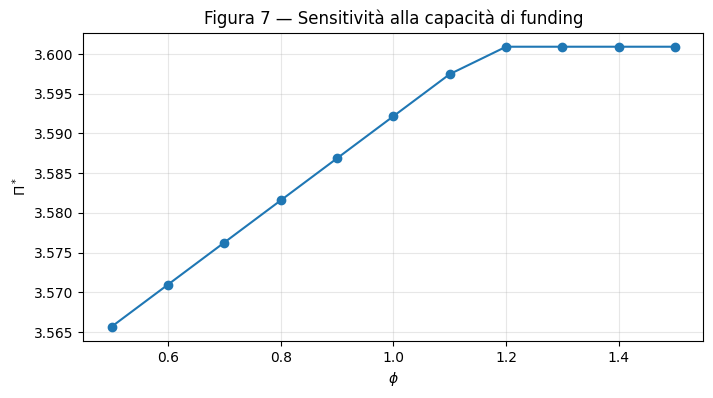

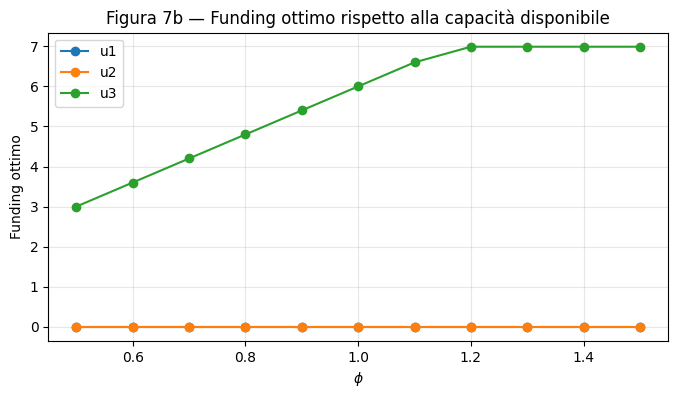

In [15]:
phi_grid=np.round(np.arange(0.50,1.501,0.10),2)
phi_rows=[]
for q in phi_grid:
    outq=solve_model(theta=1,phi=float(q),psi=1)
    phi_rows.append(row_from_solution(outq,"phi",q))
df_phi=pd.DataFrame(phi_rows)

# Tabella 7
display(df_phi)

valid_phi=df_phi[df_phi["success"]].copy()

# Figura 7
plt.figure(figsize=(8,4))
plt.plot(valid_phi["phi"],valid_phi["Pi"],marker="o",label=r"$\Pi^*$")
plt.xlabel(r"$\phi$"); plt.ylabel(r"$\Pi^*$")
plt.title(r"Figura 7 — Sensitività alla capacità di funding")
plt.grid(True,alpha=.3); plt.show()

plt.figure(figsize=(8,4))
for col in ["u1","u2","u3"]:
    plt.plot(valid_phi["phi"],valid_phi[col],marker="o",label=col)
plt.xlabel(r"$\phi$"); plt.ylabel("Funding ottimo")
plt.title("Figura 7b — Funding ottimo rispetto alla capacità disponibile")
plt.legend(); plt.grid(True,alpha=.3); plt.show()

# Tappa 8 — Sensitività rispetto a $\psi$  
**Regime B**

Si varia:

$$
\psi\in\{0.50,0.75,1.00,1.25,1.50,1.75,2.00\},
$$

mantenendo $\theta=\phi=1$.

**Controllo specifico:** $\psi$ deve comparire sia nel costo del funding nell'obiettivo sia nei coefficienti di rimborso dei bilanci temporali.

,psi,success,status,Pi,Delta_Pi,Delta_Pi_pct,x1,Delta_x1,x2,Delta_x2,x3,Delta_x3,x4,Delta_x4,g1,Delta_g1,g2,Delta_g2,g3,Delta_g3,g4,Delta_g4,u1,Delta_u1,rho_u1,u2,Delta_u2,rho_u2,u3,Delta_u3,rho_u3,prud_slack,x3_slack,u1_upper_slack,u2_upper_slack,u3_upper_slack,marg_t1_Pi,marg_t2_Pi,marg_t3_Pi,marg_t4_Pi
0,0.50,True,0,3.667166,0.07500,2.087877,0.0,0.0,51.919684,0.000000,0.0,0.0,48.080316,0.000000,6.151810,0.000000,1.566506,0.000000,0.0,0.0,2.965158,0.075000,0.0,0.0,0.0,0.0,0.0,0.0,6.0,0.0,1.0,2.115181,30.0,10.0,8.0,0.0,-0.045238,-0.040038,-0.033835,0.0
1,0.75,True,0,3.629666,0.03750,1.043938,0.0,0.0,51.919684,0.000000,0.0,0.0,48.080316,0.000000,6.151810,0.000000,1.566506,0.000000,0.0,0.0,2.927658,0.037500,0.0,0.0,0.0,0.0,0.0,0.0,6.0,0.0,1.0,2.115181,30.0,10.0,8.0,0.0,-0.045238,-0.040038,-0.033835,0.0
2,1.00,True,0,3.592166,0.00000,0.000000,0.0,0.0,51.919684,0.000000,0.0,0.0,48.080316,0.000000,6.151810,0.000000,1.566506,0.000000,0.0,0.0,2.890158,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,6.0,0.0,1.0,2.115181,30.0,10.0,8.0,0.0,-0.045238,-0.040038,-0.033835,0.0
3,1.25,True,0,3.554666,-0.03750,-1.043938,0.0,0.0,51.919684,0.000000,0.0,0.0,48.080316,0.000000,6.151810,0.000000,1.566506,0.000000,0.0,0.0,2.852658,-0.037500,0.0,0.0,0.0,0.0,0.0,0.0,6.0,0.0,1.0,2.115181,30.0,10.0,8.0,0.0,-0.045238,-0.040038,-0.033835,0.0
4,1.50,True,0,3.539156,-0.05301,-1.475704,0.0,0.0,63.734940,11.815257,0.0,0.0,36.265060,-11.815257,13.240964,7.089154,11.054157,9.487651,0.0,0.0,3.132530,0.242372,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-6.0,0.0,2.824096,30.0,10.0,8.0,6.0,-0.045238,-0.040038,-0.033835,0.0
5,1.75,True,0,3.539156,-0.05301,-1.475704,0.0,0.0,63.734940,11.815257,0.0,0.0,36.265060,-11.815257,13.240964,7.089154,11.054157,9.487651,0.0,0.0,3.132530,0.242372,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-6.0,0.0,2.824096,30.0,10.0,8.0,6.0,-0.045238,-0.040038,-0.033835,0.0
6,2.00,True,0,3.539156,-0.05301,-1.475704,0.0,0.0,63.734940,11.815257,0.0,0.0,36.265060,-11.815257,13.240964,7.089154,11.054157,9.487651,0.0,0.0,3.132530,0.242372,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-6.0,0.0,2.824096,30.0,10.0,8.0,6.0,-0.045238,-0.040038,-0.033835,0.0


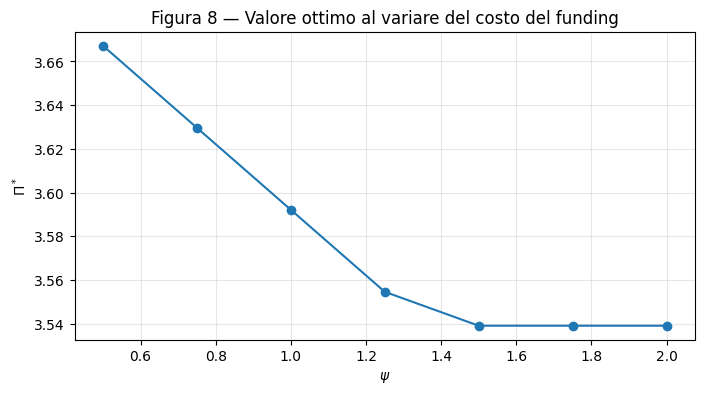

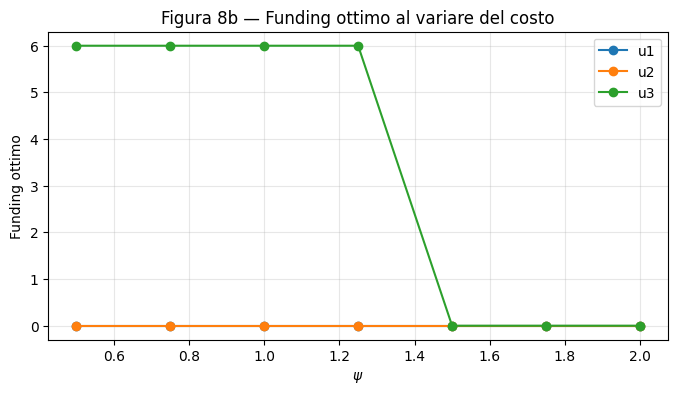

In [16]:
psi_grid=np.array([0.50,0.75,1.00,1.25,1.50,1.75,2.00])
psi_rows=[]
for q in psi_grid:
    outq=solve_model(theta=1,phi=1,psi=float(q))
    psi_rows.append(row_from_solution(outq,"psi",q))
df_psi=pd.DataFrame(psi_rows)

# Tabella 8
display(df_psi)

valid_psi=df_psi[df_psi["success"]].copy()

# Figura 8
plt.figure(figsize=(8,4))
plt.plot(valid_psi["psi"],valid_psi["Pi"],marker="o")
plt.xlabel(r"$\psi$"); plt.ylabel(r"$\Pi^*$")
plt.title(r"Figura 8 — Valore ottimo al variare del costo del funding")
plt.grid(True,alpha=.3); plt.show()

plt.figure(figsize=(8,4))
for col in ["u1","u2","u3"]:
    plt.plot(valid_psi["psi"],valid_psi[col],marker="o",label=col)
plt.xlabel(r"$\psi$"); plt.ylabel("Funding ottimo")
plt.title("Figura 8b — Funding ottimo al variare del costo")
plt.legend(); plt.grid(True,alpha=.3); plt.show()

# Tappa 9 — Confronto delle sensitività  
**Regime A**

Le tre analisi hanno significati distinti:

- $\theta$: stress sui fabbisogni iniziali;
- $\phi$: scarsità della capacità di funding;
- $\psi$: costo economico e rimborso del funding.

Il confronto non è una scenario analysis: ciascuna sensitività varia un solo driver.

In [17]:
summary = pd.DataFrame([
    {
        "driver":"theta",
        "n_config":len(df_theta),
        "n_fattibili":int(df_theta["success"].sum()),
        "Pi_min":df_theta.loc[df_theta["success"],"Pi"].min(),
        "Pi_max":df_theta.loc[df_theta["success"],"Pi"].max(),
    },
    {
        "driver":"phi",
        "n_config":len(df_phi),
        "n_fattibili":int(df_phi["success"].sum()),
        "Pi_min":df_phi.loc[df_phi["success"],"Pi"].min(),
        "Pi_max":df_phi.loc[df_phi["success"],"Pi"].max(),
    },
    {
        "driver":"psi",
        "n_config":len(df_psi),
        "n_fattibili":int(df_psi["success"].sum()),
        "Pi_min":df_psi.loc[df_psi["success"],"Pi"].min(),
        "Pi_max":df_psi.loc[df_psi["success"],"Pi"].max(),
    },
])
display(summary)

,driver,n_config,n_fattibili,Pi_min,Pi_max
0,theta,11,7,2.159921,3.592166
1,phi,11,11,3.565661,3.600918
2,psi,7,7,3.539156,3.667166


# Tappa 10 — Scenario analysis  
**Regime B**

Si risolvono esattamente:

- Standard: $(1.00,1.00,1.00)$;
- Mediamente critico: $(1.03,0.90,1.25)$;
- Critico: $(1.06,0.70,1.50)$.

Gli scenari sono deterministici e non hanno probabilità associate.

In [18]:
scenari={
    "Standard":(1.00,1.00,1.00),
    "Mediamente critico":(1.03,0.90,1.25),
    "Critico":(1.06,0.70,1.50),
}
rows=[]
scenario_outputs={}
for nome,(th,ph,ps) in scenari.items():
    o=solve_model(th,ph,ps)
    scenario_outputs[nome]=o
    row={"scenario":nome,"theta":th,"phi":ph,"psi":ps,"success":o["success"],"status":o["status"]}
    if o["success"]:
        row["Pi"]=o["Pi"]
        for j in range(4): row[f"x{j+1}"]=o["x"][j]
        for t in range(4): row[f"g{t+1}"]=o["g"][t]
        for t in range(3):
            row[f"u{t+1}"]=o["u"][t]
            row[f"rho_u{t+1}"]=o["u"][t]/(ph*u_bar[t])
    rows.append(row)

df_scenari=pd.DataFrame(rows)
Pi_standard=df_scenari.loc[df_scenari["scenario"]=="Standard","Pi"].iloc[0]
df_scenari["perdita_vs_standard"]=np.where(
    df_scenari["success"],
    Pi_standard-df_scenari["Pi"],
    np.nan
)

# Tabella 10
display(df_scenari)

assert bool(df_scenari.loc[df_scenari["scenario"]=="Standard","success"].iloc[0])
assert np.isclose(Pi_standard,Pi_bench)

,scenario,theta,phi,psi,success,status,Pi,x1,x2,x3,x4,g1,g2,g3,g4,u1,rho_u1,u2,rho_u2,u3,rho_u3,perdita_vs_standard
0,Standard,1.00,1.0,1.00,True,0,3.592166,0.000000,51.919684,0.0,48.080316,6.151810,1.566506,0.00000,2.890158,0.0,0.0,0.0,0.0,6.0,1.0,0.000000
1,Mediamente critico,1.03,0.9,1.25,True,0,3.476367,0.000000,56.675969,0.0,43.324031,8.105581,3.581303,0.00000,1.093266,0.0,0.0,0.0,0.0,5.4,1.0,0.115799
2,Critico,1.06,0.7,1.50,True,0,2.159921,62.671906,37.328094,0.0,0.000000,55.135167,36.675676,14.89573,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,1.432245


### Figure 11–14 — Confronto degli scenari

Tutti i grafici sono costruiti esclusivamente dagli scenari con soluzione valida.

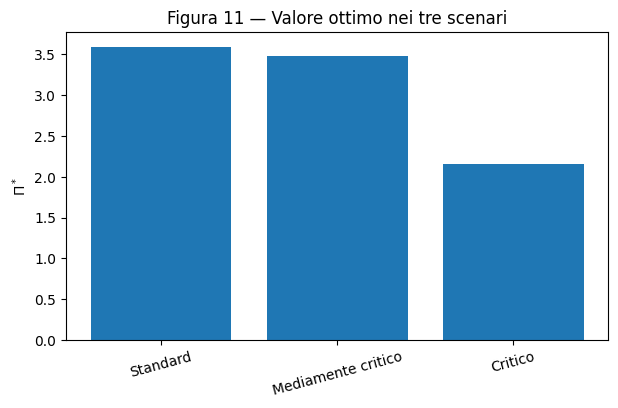

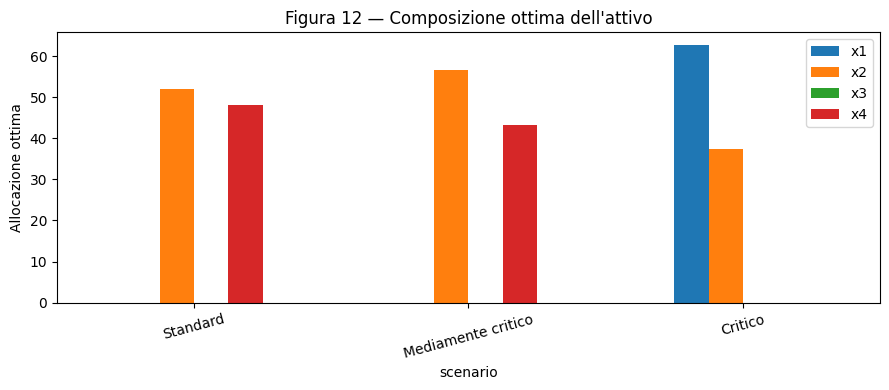

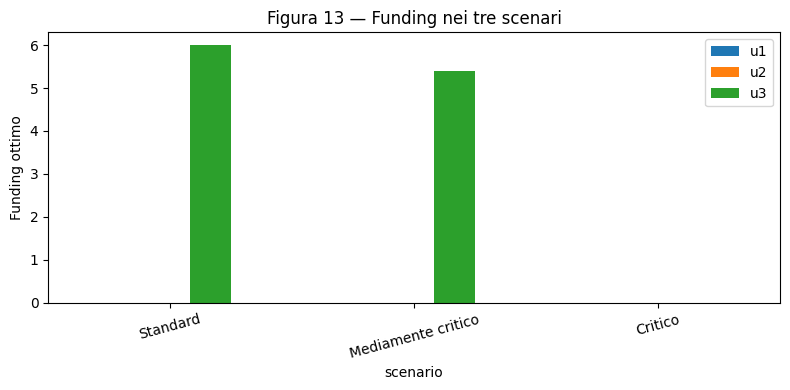

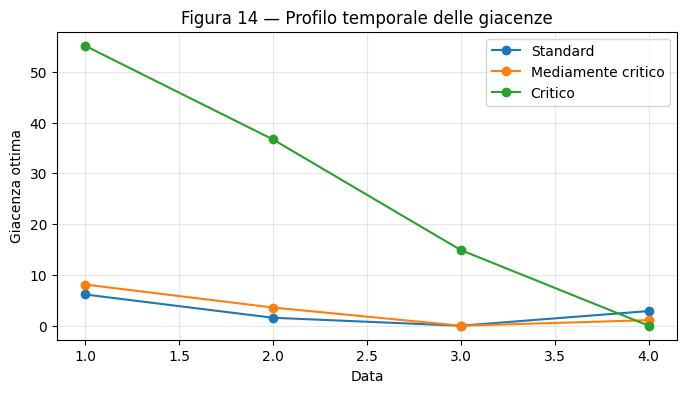

In [19]:
valid_scen=df_scenari[df_scenari["success"]].copy()

# Figura 11
plt.figure(figsize=(7,4))
plt.bar(valid_scen["scenario"],valid_scen["Pi"])
plt.ylabel(r"$\Pi^*$")
plt.title("Figura 11 — Valore ottimo nei tre scenari")
plt.xticks(rotation=15); plt.show()

# Figura 12
xcols=["x1","x2","x3","x4"]
valid_scen.set_index("scenario")[xcols].plot(kind="bar",figsize=(9,4))
plt.ylabel("Allocazione ottima")
plt.title("Figura 12 — Composizione ottima dell'attivo")
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

# Figura 13
ucols=["u1","u2","u3"]
valid_scen.set_index("scenario")[ucols].plot(kind="bar",figsize=(8,4))
plt.ylabel("Funding ottimo")
plt.title("Figura 13 — Funding nei tre scenari")
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

# Figura 14
plt.figure(figsize=(8,4))
for nome in valid_scen["scenario"]:
    r=valid_scen[valid_scen["scenario"]==nome].iloc[0]
    plt.plot([1,2,3,4],[r[f"g{i}"] for i in range(1,5)],marker="o",label=nome)
plt.xlabel("Data"); plt.ylabel("Giacenza ottima")
plt.title("Figura 14 — Profilo temporale delle giacenze")
plt.legend(); plt.grid(True,alpha=.3); plt.show()

# Tappa 11 — Controlli conclusivi  
**Regime A**

La validazione finale deve confermare:

1. coerenza dimensionale della forma solver;
2. benchmark valido e coerente con tutti i vincoli;
3. verifica perturbativa di almeno un marginale;
4. riproduzione benchmark dalla funzione parametrica;
5. variazione di un solo driver nelle sensitività;
6. doppia applicazione di $\psi$;
7. frontiera raffinata costruita da un bracket feasible/infeasible;
8. scenari esatti;
9. uso esclusivo di risultati validi;
10. notebook rieseguibile dall'inizio.

In [20]:
checks={
    "benchmark_success":bool(res_bench.success),
    "eq_residuals_ok":bool(np.max(np.abs(eq_res))<1e-7),
    "inequalities_ok":bool(np.all(ub_slack>=-1e-7)),
    "nonnegative_ok":bool(np.min(z_bench)>=-1e-7),
    "u3_upper_active":bool(abs(u_bench[2]-u_bar[2])<1e-7),
    "marginal_check_ok":bool(abs(num_der-expected)<1e-6),
    "parametric_benchmark_ok":bool(np.allclose(bench_fun["z"],z_bench,atol=1e-8)),
    "theta_grid_complete":bool(len(df_theta)==11),
    "phi_grid_complete":bool(len(df_phi)==11),
    "psi_grid_complete":bool(len(df_psi)==7),
    "frontier_bracket_found":bool(last_feasible < first_infeasible),
    "refined_bracket_found":bool(last_ref < first_ref),
    "scenarios_complete":bool(len(df_scenari)==3),
    "standard_equals_benchmark":bool(np.isclose(Pi_standard,Pi_bench)),
}
tab_checks=pd.DataFrame({"controllo":list(checks.keys()),"esito":list(checks.values())})
display(tab_checks)

if not all(checks.values()):
    raise AssertionError("Almeno un controllo conclusivo non è soddisfatto.")

print("Tutti i controlli conclusivi: OK")

,controllo,esito
0,benchmark_success,True
1,eq_residuals_ok,True
2,inequalities_ok,True
3,nonnegative_ok,True
4,u3_upper_active,True
5,marginal_check_ok,True
6,parametric_benchmark_ok,True
7,theta_grid_complete,True
8,phi_grid_complete,True
9,psi_grid_complete,True


Tutti i controlli conclusivi: OK


# Elementi quantitativi per l'interpretazione finale

Il notebook ha prodotto gli elementi necessari per discutere:

- composizione dell'attivo e profilo temporale della liquidità nel benchmark;
- uso del funding e bounds attivi;
- significato locale dei marginali;
- risposta del piano ALM ai fabbisogni più elevati;
- scarsità della capacità di funding;
- effetto del costo del funding;
- cambiamenti di regime lungo le griglie;
- perdita di fattibilità rispetto a $\theta$;
- differenza tra comparative statics e scenario analysis;
- comportamento dei tre scenari assegnati.

Le conclusioni devono restare entro i limiti del modello deterministico e stilizzato. In particolare, $\theta_{\mathrm{crit}}$ è una frontiera del modello, non una stima empirica della soglia storica di deflusso di Silicon Valley Bank.

## Cella finale dello studente — Interpretazione finanziaria

Da completare autonomamente sulla base degli output già validati.

Il commento finale deve discutere almeno:

1. ruolo dei vincoli e bounds attivi;
2. ruolo del funding;
3. differenze tra $\theta$, $\phi$ e $\psi$;
4. significato della frontiera di fattibilità;
5. differenza tra sensitività univariate e scenari;
6. limiti del modello e distinzione rispetto ai fatti storici di Silicon Valley Bank.